# Emoji Classification Challenge (Computer Vision)

**Kaggle competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ](https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50) <br>
**Group:** _Isabelle Liew, Norelle Chy, Georg RIEKHAKAINEN, Thien-Anh Nguyen_

**Task:** predict which provider (apple, google, whatsapp, facebook, samsung, mozilla, messenger) drew each emoji image. Kaggle metric: accuracy.

**Final approach:** the pretrained Vision Transformer `google/vit-base-patch16-224-in21k`, fine-tuned on the training images with a class-weighted loss to handle class imbalance.

This notebook runs the final pipeline from top to bottom: setup → data download → preprocessing → training → validation → test predictions → `submission.csv` → `README.md`. Our earlier experiments (custom CNN, ResNet101 transfer learning, data augmentation) are in the experiments notebook `submission.ipynb`.

**Contents**
0. How to run (reproducibility)
1. Setup
2. Data
3. Preprocessing
4. Train / validation split and class weights
5. Model
6. Training
7. Validation results
8. Test predictions and `submission.csv`
9. Generate `README.md` and `requirements.txt`
10. Download the output files

## AI usage (transparency)

- The exploratory notebook (custom CNN, ResNet101 transfer learning, first ViT fine-tuning, data augmentation tests) was written by the group; external code sources are cited in comments there.
- **This final notebook** was reorganised, cleaned up and documented with the help of **Claude (Anthropic)**, starting from our exploratory notebook. Claude helped to:
  - restructure the ViT pipeline into one notebook that runs top to bottom on Google Colab, with explanatory text cells and comments;
  - add the reproducibility setup (pinned library versions, seeds, one configuration cell) and the generation of `README.md` and `requirements.txt`;
  - identify and fix errors from the original code (Mac-only dependencies, missing packages, inconsistent image conversion between training and test images, submission file format) and library compatibility issues on Colab.
- All modelling decisions (model choice, preprocessing, class weights, split, hyperparameters) come from our own experiments, and every part of the code was reviewed by the group.
- Prompt given to Claude (verbatim):
  > "can you give me the full proper notebook that can run on colab, one that has like a proper structure and text cells and comments and explanations and reasonings behind decisions etc. Also include the reproducibility steps in the notebook in detail, also include a create readme code so that we basically have everything that we need inside this notebook, also make it such that the readme will be downloaded in the same way like the csv file, so not download into anyone's drive, include anything else we might need"

## 0. How to run (reproducibility)

The notebook is designed for **Google Colab** so it runs the same way on any computer (Windows, macOS or Linux): everything runs in the browser and nothing has to be installed locally.

**Step 1: Open the notebook in Colab**
- From GitHub: open `https://colab.research.google.com/github/georgerieh/computer-vision-class/blob/main/CV_Emoji Project_CG_LYC_TN_R.ipynb`
- Or: in Colab, *File → Upload notebook* and choose this `.ipynb` file.

**Step 2: Choose the runtime**
*Runtime → Change runtime type*:
- **Hardware accelerator: T4 GPU** (training a ViT on CPU would take many hours).
- **Runtime version: `2026.07`** (recommended). Pinning the Colab version freezes Python (3.12) and TensorFlow (2.20.0), so later Colab updates cannot break the notebook. Leaving it on "Latest" also works in most cases: the install cell below forces the exact library versions anyway.

**Step 3: Give access to the data** (choose ONE option)
- **Option A: Kaggle login (automatic download).**
  1. On Kaggle: make sure you joined the competition and accepted its rules (otherwise the download is refused).
  2. Kaggle → *Settings → API → Create New Token* to get your API key.
  3. When the notebook reaches the `kagglehub.login()` cell (just before section 2.1), a login form appears: enter your Kaggle username and API key.
  4. If section 2.1 then fails with a credentials error, the form was not filled in yet: log in, re-run section 2.1, and continue from there.
- **Option B: Upload the zip manually.** Download the data zip from the competition's *Data* tab and drag it into the Colab *Files* panel (folder `/content`). The notebook finds and unzips it automatically. The zip is about 257 MB, so wait for the upload to finish before running.

**Step 4: Run everything**
1. *Runtime → Run all*.
2. **First run only:** the install cell installs the pinned library versions and then restarts the session on purpose (Colab may show "Your session crashed", this is expected). Then click *Runtime → Run all* **a second time**. From then on the install cell detects the correct versions and does nothing.
3. The whole run takes roughly 40–70 minutes on a T4 GPU: about 5–10 minutes to preprocess all images (section 3), most of the rest for training.

**Step 5: Outputs**
At the end, `submission.csv`, `README.md` and `requirements.txt` are downloaded to your computer through the browser (nothing is written to Google Drive). If the browser asks whether the page may download multiple files, click *Allow*. All outputs are also kept in `/content/outputs/` while the session is open.

**What "reproducible" means here**
- Library versions are pinned (install cell) and printed.
- All randomness we control is seeded with `SEED = 42`: the shuffling and the train/validation split, the training batch order, and the initialisation of the new classification layer.
- GPUs still use some non-deterministic operations for speed, so a rerun can differ slightly (typically a few tenths of a percent of accuracy). Setting `DETERMINISTIC = True` in the configuration cell removes this, at the cost of slower training.
- All settings (seed, split size, epochs, learning rate, …) are in one configuration cell (section 1.3).

## 1. Setup

### 1.1 Install pinned library versions

**Why:** these libraries change quickly, so we lock exact versions.
- Recent `transformers` releases (v5+) no longer include TensorFlow models, so we pin `transformers` 4.57.1, which still has `TFViTForImageClassification`.
- `tf-keras` (Keras 2) is required by the TensorFlow models in `transformers`; Colab's default Keras 3 does not work with them.
- `datasets` (Hugging Face) is used to build and preprocess the image dataset.

If anything had to be installed, the cell restarts the session. Run all cells again after that.

In [1]:
# 1.1 Install pinned versions (installs only what is missing or different, then restarts once)
import importlib.metadata as metadata
import os
import subprocess
import sys

PINNED_VERSIONS = {
    "tensorflow": "2.20.0",
    "tf-keras": "2.20.1",       # Keras 2 for TensorFlow 2.20 (needed by transformers' TF models)
    "transformers": "4.57.1",   # last 4.x line; v5 removed TensorFlow support
    "datasets": "4.0.0",
    "scikit-learn": "1.6.1",
    "kagglehub": "1.0.2",
}

def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None

to_install = [f"{pkg}=={ver}" for pkg, ver in PINNED_VERSIONS.items()
              if installed_version(pkg) != ver]

if to_install:
    print("Installing:", " ".join(to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    print("\nInstallation done. Restarting the session so the new versions are used.")
    print(">>> When the session has restarted: Runtime -> Run all again. <<<")
    os.kill(os.getpid(), 9)   # restart the Python process (Colab reconnects automatically)
else:
    print("All pinned versions already installed:")
    for pkg, ver in PINNED_VERSIONS.items():
        print(f"  {pkg}=={ver}")

All pinned versions already installed:
  tensorflow==2.20.0
  tf-keras==2.20.1
  transformers==4.57.1
  datasets==4.0.0
  scikit-learn==1.6.1
  kagglehub==1.0.2


### 1.2 Imports

`TF_USE_LEGACY_KERAS=1` must be set **before** TensorFlow is imported, so that `tf.keras` and `transformers` both use Keras 2 (`tf-keras`). `USE_TF=1` tells `transformers` to use its TensorFlow models.

In [2]:
# 1.2 Imports
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # use Keras 2 (tf-keras) everywhere
os.environ["USE_TF"] = "1"                # transformers: use the TensorFlow implementation
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info messages

import math
import platform
import time
import zipfile
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import tensorflow as tf
import tf_keras as keras

import datasets
import sklearn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.utils import class_weight

import transformers
from transformers import (DefaultDataCollator, TFViTForImageClassification, ViTImageProcessor,
                          create_optimizer)

import kagglehub

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:          # running outside Colab (e.g. local Jupyter)
    IN_COLAB = False

# Record the exact environment (also written to README.md and requirements.txt at the end)
ENV_VERSIONS = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "tf-keras": keras.__version__,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "scikit-learn": sklearn.__version__,
    "kagglehub": kagglehub.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "matplotlib": matplotlib.__version__,
}
for name, version in ENV_VERSIONS.items():
    print(f"{name:<13} {version}")

mismatches = {p: (ENV_VERSIONS.get(p), v) for p, v in PINNED_VERSIONS.items()
              if ENV_VERSIONS.get(p) != v}
if mismatches:
    print("\nWARNING - versions differ from the pinned ones (installed, pinned):", mismatches)
    print("Re-run cell 1.1, or restart the session and run all again.")

python        3.13.16
tensorflow    2.20.0
tf-keras      2.20.1
transformers  4.57.1
datasets      4.0.0
scikit-learn  1.6.1
kagglehub     1.0.2
numpy         2.1.3
pandas        2.2.3
pillow        11.3.0
matplotlib    3.10.0


In [3]:
# Compatibility patch: datasets 4.0.0 looks for torchvision.io.VideoReader,
# which recent torchvision versions removed. We never use video, so a dummy class is enough.
try:
    import torchvision.io
    if not hasattr(torchvision.io, "VideoReader"):
        class _VideoReaderPlaceholder:
            pass
        torchvision.io.VideoReader = _VideoReaderPlaceholder
except ImportError:
    pass  # torchvision not installed -> nothing to patch

### 1.3 Configuration

Every setting that affects the results is defined here, so a rerun uses exactly the same choices.

In [4]:
# 1.3 Configuration
SEED = 42
DETERMINISTIC = False      # True = bit-for-bit identical GPU runs, but slower training

# Project information (used in README.md)
GROUP_MEMBERS = ["Isabelle Liew", "Norelle Chy", "Georg RIEKHAKAINEN", "Thien-Anh Nguyen"]
KAGGLE_TEAM_NAME = "CG_LYC_TN_R"
REPO_URL = "https://github.com/georgerieh/computer-vision-class"
NOTEBOOK_NAME = "CV_Emoji Project_CG_LYC_TN_R.ipynb"
COLAB_URL = "https://colab.research.google.com/github/georgerieh/computer-vision-class/blob/main/" + NOTEBOOK_NAME
COMPETITION_SLUG = "2-computer-vision-2026-b-sc-aidams-final-proj"
COMPETITION_URL = "https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50"

# Classes (fixed order = the integer ids used by the model)
kaggle_classes = ["apple", "google", "whatsapp", "facebook", "samsung", "mozilla", "messenger"]
class_to_int = {name: i for i, name in enumerate(kaggle_classes)}
int_to_class = {i: name for i, name in enumerate(kaggle_classes)}

# Model and training
model_name = "google/vit-base-patch16-224-in21k"   # ViT-Base, 16x16 patches, pretrained on ImageNet-21k
test_size = 0.33            # share of the labelled images held out for validation (stratified)
batch_size = 16             # images per training step (same value as in our experiments); fits in a T4 GPU's memory, use 8 only if training stops with an out-of-memory error
num_epochs = 5              # maximum number of epochs (early stopping may stop earlier)
init_lr = 2e-5              # small learning rate: we adjust pretrained weights, not learn from scratch
weight_decay_rate = 0.01    # AdamW weight decay (light regularisation)
warmup_ratio = 0.1          # first 10% of steps: learning rate rises from 0 to init_lr
early_stop_patience = 1     # stop as soon as validation accuracy does not improve for 1 epoch

# Paths
WORK_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_ROOT = WORK_DIR / "data"
OUTPUT_DIR = WORK_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "vit_emoji_class"
WEIGHTS_PATH = OUTPUT_DIR / "vit_emoji_class.h5"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", WORK_DIR)
print("Outputs will be saved in:", OUTPUT_DIR)

Working directory: /content
Outputs will be saved in: /content/outputs


### 1.4 Seeds and GPU check

`keras.utils.set_random_seed` seeds Python's `random`, NumPy and TensorFlow in one call.

In [5]:
# 1.4 Seeds and hardware
keras.utils.set_random_seed(SEED)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic GPU operations: ON")

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("GPU found:", [tf.config.experimental.get_device_details(g).get("device_name", g.name) for g in gpus])
else:
    print("WARNING: no GPU found. Training will be very slow.")
    print("In Colab: Runtime -> Change runtime type -> T4 GPU, then run all again.")

GPU found: ['Tesla T4']


## 2. Data

### 2.1 Download / locate the data

The cell tries, in this order:
1. data already extracted in `data/` (when the notebook is re-run in the same session);
2. a competition zip uploaded manually to `/content` (Option B in section 0);
3. download from Kaggle with `kagglehub`, using the account you logged in with in the `kagglehub.login()` cell (Option A).

The original image files are never modified. Preprocessing happens in memory only.

In [8]:
# Log in to Kaggle (enter your username + API key in the form) so the data can be downloaded in section 2.1
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [9]:
# 2.1 Locate or download the competition data

def find_data_dir(root):
    """Return the folder that contains train_labels.csv (searching sub-folders), or None."""
    root = Path(root)
    if not root.exists():
        return None
    hits = sorted(root.rglob("train_labels.csv"))
    return hits[0].parent if hits else None

def get_data_dir():
    # 1) Already extracted earlier in this session
    data_dir = find_data_dir(DATA_ROOT)
    if data_dir:
        print("Using data already extracted in", data_dir)
        return data_dir
    # 2) Zip uploaded manually to the working directory
    for zip_path in sorted(WORK_DIR.glob("*.zip")):
        with zipfile.ZipFile(zip_path) as zf:
            if any(name.endswith("train_labels.csv") for name in zf.namelist()):
                print(f"Extracting {zip_path.name} ...")
                zf.extractall(DATA_ROOT)
                return find_data_dir(DATA_ROOT)
    # 3) Download from Kaggle
    print("Downloading from Kaggle ...")
    download_path = kagglehub.competition_download(COMPETITION_SLUG)
    return find_data_dir(download_path)

DATA_DIR = get_data_dir()
assert DATA_DIR is not None, "train_labels.csv not found in the downloaded/extracted data."
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
print("Data folder:", DATA_DIR)
print("Contents:", sorted(p.name for p in DATA_DIR.iterdir()))

100%|██████████| 248M/248M [00:03<00:00, 78.1MB/s]

Extracting files...


Data folder: /root/.cache/kagglehub/competitions/2-computer-vision-2026-b-sc-aidams-final-proj
Contents: ['test', 'train', 'train_labels.csv']


### 2.2 Labels and file checks

Image file names are the ids (e.g. `00001.png` → Id 1). We check that every label has an image, that the classes are the expected ones, and that the test ids match `sample_submission.csv`.

In [10]:
# 2.2 Labels, file lists and consistency checks
labels_df = pd.read_csv(DATA_DIR / "train_labels.csv")
assert list(labels_df.columns[:2]) == ["Id", "Label"], labels_df.columns
assert set(labels_df["Label"]) == set(kaggle_classes), set(labels_df["Label"]) ^ set(kaggle_classes)

train_files = {int(p.stem): p for p in TRAIN_DIR.glob("*.png")}
test_files = {int(p.stem): p for p in TEST_DIR.glob("*.png")}

labels_df["path"] = labels_df["Id"].map(train_files)
assert labels_df["path"].notna().all(), "Some labelled ids have no image file."
labels_df["y"] = labels_df["Label"].map(class_to_int).astype("int32")

# Submission format and test-id order come from sample_submission.csv when it exists
sample_path = DATA_DIR / "sample_submission.csv"
if sample_path.exists():
    sample_submission = pd.read_csv(sample_path)
    ID_COL, LABEL_COL = sample_submission.columns[:2]
    test_ids = sample_submission[ID_COL].astype(int).tolist()
    assert set(test_ids) == set(test_files), "Test images and sample_submission ids differ."
else:
    ID_COL, LABEL_COL = "Id", "Label"
    test_ids = sorted(test_files)
test_paths = [test_files[i] for i in test_ids]

print(f"Train images: {len(labels_df)} | Test images: {len(test_paths)}")
print(f"Submission columns: {ID_COL}, {LABEL_COL}")
labels_df.head()

Train images: 9879 | Test images: 9879
Submission columns: Id, Label


,Id,Label,path,y
0,1,samsung,/root/.cache/kagglehub/competitions/2-computer...,4
1,2,apple,/root/.cache/kagglehub/competitions/2-computer...,0
2,3,facebook,/root/.cache/kagglehub/competitions/2-computer...,3
3,4,facebook,/root/.cache/kagglehub/competitions/2-computer...,3
4,5,google,/root/.cache/kagglehub/competitions/2-computer...,1


### 2.3 Class distribution

The dataset is imbalanced: mozilla and messenger have far fewer images than the other classes. This is handled with class weights in section 4.

In [11]:
# 2.3 Images per class
labels_df.groupby("Label").size().reindex(kaggle_classes).to_frame("images")

,images
Label,
apple,1924
google,1877
whatsapp,1644
facebook,1667
samsung,1790
mozilla,397
messenger,580


## 3. Preprocessing

- The images are loaded into a Hugging Face `datasets.Dataset` (image path + integer label).
- Every image is converted to 3-channel RGB with `.convert("RGB")`. The PNGs have a transparency (alpha) channel, but the model expects 3 channels. **The same conversion is used for the test images in section 8**, so training and test images are prepared identically.
- `ViTImageProcessor` (the processor that belongs to the pretrained model) then resizes each image to 224×224 and normalises the pixel values exactly as during the model's pretraining.
- No data augmentation: in our experiments it gave lower results than without it.
- Preprocessing runs in groups of 128 images (`batch_size=128` in section 3.3) instead of the default 1,000, which ran out of memory on Colab. This group size only affects memory use; every image is processed the same way.

In [12]:
# 3.1 Processor and preprocessing function
feature_extractor = ViTImageProcessor.from_pretrained(model_name)   # resize + normalise like pretraining

def to_rgb(img):
    """Drop the alpha channel -> 3-channel RGB. Used for BOTH training and test images."""
    return img.convert("RGB")

def process(batch):
    # Safeguard: convert all images in the batch to RGB
    rgb_images = [to_rgb(img) for img in batch["img"]]
    batch.update(feature_extractor(rgb_images))
    return batch

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [13]:
# 3.2 Build the dataset (image path + label) from train_labels.csv
def create_image_folder_dataset(root_path):
    """Creates a `Dataset` with one row per training image: the image file and its integer label."""
    features = datasets.Features({
        "img": datasets.Image(),
        "label": datasets.features.ClassLabel(names=kaggle_classes),
    })

    y_train = pd.read_csv(os.path.join(root_path, "train_labels.csv"))
    label_data_files = [class_to_int[label] for label in y_train["Label"]]

    # Full path of each image file (file names are the zero-padded ids, e.g. 00001.png)
    img_data_files = [
        os.path.join(root_path, "train", f"{str(x).zfill(5)}.png")
        for x in y_train["Id"]
    ]

    print(f"Labels count: {len(label_data_files)}")
    print(f"Images count: {len(img_data_files)}")

    ds = datasets.Dataset.from_dict(
        {"img": img_data_files, "label": label_data_files},
        features=features,
    )
    return ds

emoji_ds = create_image_folder_dataset(str(DATA_DIR))
emoji_ds = emoji_ds.rename_column("label", "labels")   # Keras/transformers expect the name "labels"

Labels count: 9879
Images count: 9879


In [14]:
# 3.3 Preprocess every image (resize + normalise); takes a few minutes, results are cached on disk.
processed_dataset = emoji_ds.map(process, batched=True, batch_size=128)
processed_dataset

Map:   0%|          | 0/9879 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Dataset({
    features: ['img', 'labels', 'pixel_values'],
    num_rows: 9879
})

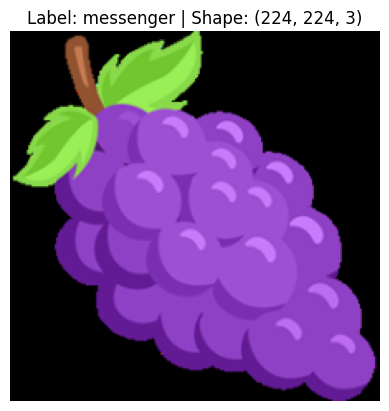

In [15]:
# 3.4 Show one preprocessed image (un-normalised for display) to check the preprocessing
rng_show = np.random.default_rng(SEED)
inx = int(rng_show.integers(0, len(processed_dataset)))

img_data = np.array(processed_dataset[inx]["pixel_values"])   # shape: (3, 224, 224)
img_data = np.transpose(img_data, (1, 2, 0))                     # (224, 224, 3) for matplotlib

mean = np.array(feature_extractor.image_mean)   # the processor's own normalisation values
std = np.array(feature_extractor.image_std)
img_data = np.clip(std * img_data + mean, 0, 1)

plt.imshow(img_data)
plt.axis("off")
plt.title(f"Label: {int_to_class[processed_dataset[inx]['labels']]} | Shape: {img_data.shape}")
plt.show()

## 4. Train / validation split and class weights

- **Stratified 67/33 split**, seeded: the validation set keeps the same class proportions as the full data (important for the rare classes). The validation set is used for early stopping and to measure accuracy, since the test labels are hidden.
- **Class weights ("balanced")**: weight = n_samples / (n_classes × n_samples_of_class). Rare classes (mozilla, messenger) get a larger weight in the loss, so the model is penalised more for missing them. We compared this with undersampling every class to the size of the smallest one; class weights kept all the data and worked better.

In [16]:
# 4.1 Shuffle and stratified split (seeded)
processed_dataset_split = processed_dataset.shuffle(seed=SEED).train_test_split(
    test_size=test_size, stratify_by_column="labels", seed=SEED
)
processed_dataset_split

DatasetDict({
    train: Dataset({
        features: ['img', 'labels', 'pixel_values'],
        num_rows: 6618
    })
    test: Dataset({
        features: ['img', 'labels', 'pixel_values'],
        num_rows: 3261
    })
})

In [17]:
# 4.2 Class weights (from all labelled images)
y_strings = labels_df["Label"]
y_train = np.array([class_to_int[label] for label in y_strings])
class_weights = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train,
)
class_weights_dict = dict(enumerate(class_weights))
print("Class weights:", {int_to_class[i]: round(float(w), 3) for i, w in class_weights_dict.items()})

Class weights: {'apple': 0.734, 'google': 0.752, 'whatsapp': 0.858, 'facebook': 0.847, 'samsung': 0.788, 'mozilla': 3.555, 'messenger': 2.433}


## 5. Model

- `TFViTForImageClassification` = pretrained ViT encoder + a **new classification layer with 7 outputs** (randomly initialised, seeded). All layers are fine-tuned.
- **Optimizer:** AdamW (Adam with weight decay) from `create_optimizer`: the learning rate warms up over the first 10% of steps, then decays linearly to 0.
- **Loss:** sparse categorical cross-entropy computed on the logits, multiplied by the class weight of each image's true class.
- **Metrics:** accuracy (the Kaggle metric), top-2 and top-3 accuracy.

**Loading note:** the model is loaded from the checkpoint's TensorFlow weights file (`tf_model.h5`) with `use_safetensors=False`. Loading the `model.safetensors` file into the TensorFlow model fails with the current `safetensors` library (`TypeError: 'builtins.safe_open' object is not iterable`). Both files contain the same pretrained weights.

In [18]:
# 5.1 Load the pretrained model with a new 7-class head
keras.utils.set_random_seed(SEED)   # same initial weights for the new classification layer on every run
model = TFViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(kaggle_classes),
    id2label=int_to_class,
    label2id=class_to_int,
    ignore_mismatched_sizes=True,
    use_safetensors=False,   # load the TensorFlow weights file (tf_model.h5); see note in section 5
)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

tf_model.h5:   0%|          | 0.00/346M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at google/vit-base-patch16-224-in21k were not used when initializing TFViTForImageClassification: ['vit/pooler/dense/bias:0', 'vit/pooler/dense/kernel:0']
- This IS expected if you are initializing TFViTForImageClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFViTForImageClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized:

In [19]:
# 5.2 Weighted loss, optimizer, metrics, compile
class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)

def weighted_sparse_categorical_crossentropy(y_true, y_pred):
    """Cross-entropy per image (from logits), multiplied by the weight of the image's true class."""
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    unweighted_loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    weights = tf.gather(class_weights_tensor, y_true)
    return tf.reduce_mean(unweighted_loss * weights)

num_train_samples = len(processed_dataset_split["train"])
num_train_steps = math.ceil(num_train_samples / batch_size) * num_epochs
num_warmup_steps = int(warmup_ratio * num_train_steps)
optimizer, lr_schedule = create_optimizer(
    init_lr=init_lr,
    num_train_steps=num_train_steps,
    weight_decay_rate=weight_decay_rate,
    num_warmup_steps=num_warmup_steps,
)

metrics = [
    keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
    keras.metrics.SparseTopKCategoricalAccuracy(2, name="top-2-accuracy"),
    keras.metrics.SparseTopKCategoricalAccuracy(3, name="top-3-accuracy"),
]

model.compile(
    optimizer=optimizer,
    loss=weighted_sparse_categorical_crossentropy,
    metrics=metrics,
)
model.summary()
print(f"Training steps: {num_train_steps} (warm-up: {num_warmup_steps})")

Model: "tf_vi_t_for_image_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vit (TFViTMainLayer)        multiple                  85798656  
                                                                 
 classifier (Dense)          multiple                  5383      
                                                                 
Total params: 85804039 (327.32 MB)
Trainable params: 85804039 (327.32 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Training steps: 2070 (warm-up: 207)


## 6. Training

- The training batches are shuffled every epoch; the validation set is not shuffled, so its predictions can be matched to its labels in section 7.
- **Early stopping** on validation accuracy with patience 1: training stops as soon as one epoch does not improve validation accuracy. The weights of the last epoch are kept.
- TensorBoard logs are written to `outputs/logs`; the trained model is saved to `outputs/vit_emoji_class/` and `outputs/vit_emoji_class.h5`.

In [20]:
# 6.1 tf.data pipelines
data_collator = DefaultDataCollator(return_tensors="tf")

tf_train_ds = processed_dataset_split["train"].to_tf_dataset(
    columns="pixel_values",
    label_cols="labels",
    shuffle=True,
    batch_size=batch_size,
    collate_fn=data_collator,
)

tf_val_ds = processed_dataset_split["test"].to_tf_dataset(
        columns="pixel_values",
    label_cols="labels",
    shuffle=False,
    batch_size=batch_size,
    collate_fn=data_collator,
)

In [21]:
# 6.2 Train
callbacks = [
    keras.callbacks.TensorBoard(log_dir=str(OUTPUT_DIR / "logs")),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=early_stop_patience),
    keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log.csv")),
]

start = time.time()
train_results = model.fit(
    tf_train_ds,
    validation_data=tf_val_ds,
    callbacks=callbacks,
    epochs=num_epochs,
)
training_minutes = (time.time() - start) / 60
print(f"Training time: {training_minutes:.1f} min | epochs run: {len(train_results.history['loss'])}")

Epoch 1/5
414/414 [==============================] - 410s 942ms/step - loss: 1.2784 - accuracy: 0.6109 - top-2-accuracy: 0.7608 - top-3-accuracy: 0.8354 - val_loss: 0.5258 - val_accuracy: 0.9056 - val_top-2-accuracy: 0.9733 - val_top-3-accuracy: 0.9899
Epoch 2/5
414/414 [==============================] - 391s 944ms/step - loss: 0.3948 - accuracy: 0.9235 - top-2-accuracy: 0.9766 - top-3-accuracy: 0.9900 - val_loss: 0.2968 - val_accuracy: 0.9436 - val_top-2-accuracy: 0.9865 - val_top-3-accuracy: 0.9951
Epoch 3/5
414/414 [==============================] - 392s 948ms/step - loss: 0.2314 - accuracy: 0.9601 - top-2-accuracy: 0.9876 - top-3-accuracy: 0.9958 - val_loss: 0.2162 - val_accuracy: 0.9595 - val_top-2-accuracy: 0.9929 - val_top-3-accuracy: 0.9963
Epoch 4/5
414/414 [==============================] - 391s 944ms/step - loss: 0.1497 - accuracy: 0.9798 - top-2-accuracy: 0.9946 - top-3-accuracy: 0.9985 - val_loss: 0.1917 - val_accuracy: 0.9650 - val_top-2-accuracy: 0.9933 - val_top-3-accur

In [22]:
# 6.3 Save the model
model.save_pretrained(str(MODEL_DIR))
feature_extractor.save_pretrained(str(MODEL_DIR))
model.save_weights(str(WEIGHTS_PATH))
print("Saved to", MODEL_DIR, "and", WEIGHTS_PATH)

Saved to /content/outputs/vit_emoji_class and /content/outputs/vit_emoji_class.h5


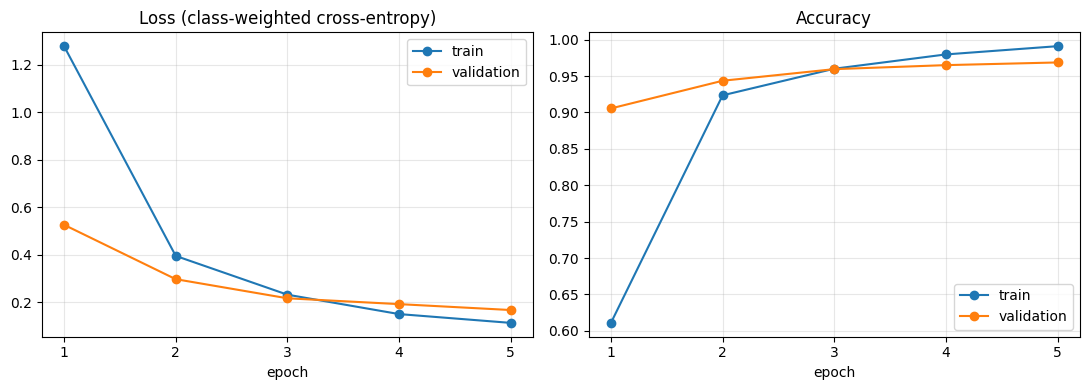

,loss,accuracy,top-2-accuracy,top-3-accuracy,val_loss,val_accuracy,val_top-2-accuracy,val_top-3-accuracy
0,1.2784,0.6109,0.7608,0.8354,0.5258,0.9056,0.9733,0.9899
1,0.3948,0.9235,0.9766,0.9900,0.2968,0.9436,0.9865,0.9951
2,0.2314,0.9601,0.9876,0.9958,0.2162,0.9595,0.9929,0.9963
3,0.1497,0.9798,0.9946,0.9985,0.1917,0.9650,0.9933,0.9957
4,0.1126,0.9911,0.9970,0.9991,0.1668,0.9687,0.9929,0.9963


In [23]:
# 6.4 Learning curves
hist = pd.DataFrame(train_results.history)
epochs_axis = np.arange(1, len(hist) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_axis, hist["loss"], marker="o", label="train")
axes[0].plot(epochs_axis, hist["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss (class-weighted cross-entropy)")
axes[1].plot(epochs_axis, hist["accuracy"], marker="o", label="train")
axes[1].plot(epochs_axis, hist["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_xticks(epochs_axis)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
plt.show()
display(hist.round(4))

## 7. Validation results

Accuracy is the Kaggle metric. Because the classes are imbalanced, we also report **balanced accuracy** (the average of per-class recalls), the per-class report and the **confusion matrix**, to check whether the rare classes (mozilla, messenger) are confused with others.

In [24]:
# 7.1 Predictions on the validation set
val_true, val_logits = [], []
for pixel_batch, label_batch in tf_val_ds:
    val_logits.append(model(pixel_values=pixel_batch, training=False).logits.numpy())
    val_true.append(label_batch.numpy())
val_true = np.concatenate(val_true)
val_logits = np.concatenate(val_logits)
val_pred = val_logits.argmax(axis=1)

val_accuracy = accuracy_score(val_true, val_pred)
val_balanced_accuracy = balanced_accuracy_score(val_true, val_pred)
val_top3 = float(np.mean([t in np.argsort(l)[-3:] for t, l in zip(val_true, val_logits)]))
print(f"Validation accuracy:          {val_accuracy:.4f}")
print(f"Validation balanced accuracy: {val_balanced_accuracy:.4f}")
print(f"Validation top-3 accuracy:    {val_top3:.4f}\n")

report_text = classification_report(val_true, val_pred, labels=np.arange(len(kaggle_classes)),
                                    target_names=kaggle_classes, digits=3)
print(report_text)
(OUTPUT_DIR / "validation_report.txt").write_text(report_text)

Validation accuracy:          0.9687
Validation balanced accuracy: 0.9682
Validation top-3 accuracy:    0.9963

              precision    recall  f1-score   support

       apple      0.959     0.962     0.961       635
      google      0.971     0.981     0.976       620
    whatsapp      0.965     0.963     0.964       543
    facebook      0.978     0.955     0.966       550
     samsung      0.980     0.981     0.981       591
     mozilla      0.947     0.962     0.955       131
   messenger      0.959     0.974     0.966       191

    accuracy                          0.969      3261
   macro avg      0.966     0.968     0.967      3261
weighted avg      0.969     0.969     0.969      3261



596

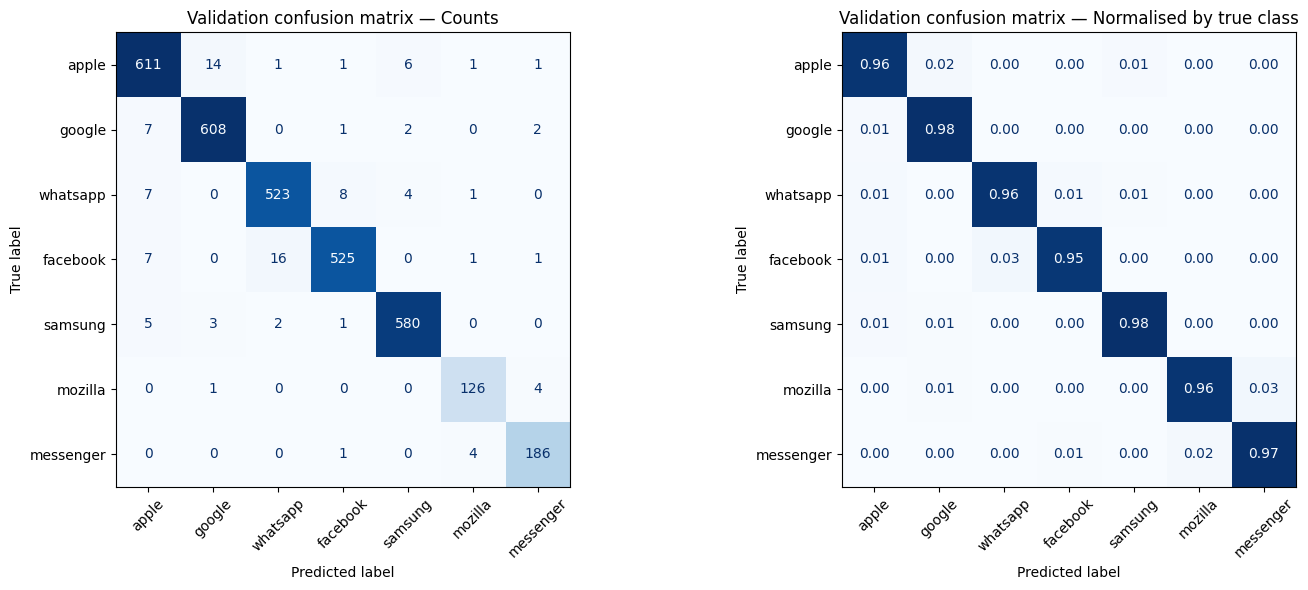

In [25]:
# 7.2 Confusion matrix (counts and row-normalised = recall per class)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Normalised by true class")]:
    cm = confusion_matrix(val_true, val_pred, labels=np.arange(len(kaggle_classes)), normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=kaggle_classes).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(f"Validation confusion matrix — {title}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 8. Test predictions and `submission.csv`

- The saved weights are reloaded from `vit_emoji_class.h5`, so this section also works as a check that the saved file is usable.
- Each test image goes through **the same steps as the training images**: `to_rgb` (alpha channel dropped) → `ViTImageProcessor`.
- The CSV uses the column names and id order of `sample_submission.csv` and is checked before saving.

In [26]:
# 8.1 Predict the test set
model.load_weights(str(WEIGHTS_PATH))

def image_gen(paths, ids):
    for p, img_id in zip(paths, ids):
        with Image.open(p) as img:
            pixel_values = feature_extractor(images=to_rgb(img), return_tensors="np")["pixel_values"][0]
        yield pixel_values, img_id

dataset = tf.data.Dataset.from_generator(
    lambda: image_gen(test_paths, test_ids),
    output_signature=(
        tf.TensorSpec(shape=(3, 224, 224), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.int64),
    ),
).batch(32).prefetch(tf.data.AUTOTUNE)

results = []
pbar = tqdm(total=len(test_paths), desc="Test predictions")
for pixel_batch, id_batch in dataset:
    preds = tf.argmax(model(pixel_values=pixel_batch, training=False).logits, axis=-1).numpy()
    for img_id, pred_idx in zip(id_batch.numpy(), preds):
        results.append({ID_COL: int(img_id), LABEL_COL: kaggle_classes[pred_idx]})
    pbar.update(len(preds))
pbar.close()

submission = pd.DataFrame(results, columns=[ID_COL, LABEL_COL])

# Format checks
assert len(submission) == len(test_paths) and submission[ID_COL].is_unique
assert submission[ID_COL].tolist() == test_ids
assert set(submission[LABEL_COL]) <= set(kaggle_classes)

SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
print("Saved", SUBMISSION_PATH, submission.shape)
display(submission.head())

# Predicted class shares vs. training class shares (a large gap would be suspicious)
display(pd.DataFrame({
    "train share": labels_df["Label"].value_counts(normalize=True),
    "test predicted share": submission[LABEL_COL].value_counts(normalize=True),
}).reindex(kaggle_classes).round(3))

Test predictions:   0%|          | 0/9879 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Saved /content/outputs/submission.csv (9879, 2)


,Id,Label
0,10001,google
1,10002,messenger
2,10003,samsung
3,10004,whatsapp
4,10005,samsung


,train share,test predicted share
Label,,
apple,0.195,0.191
google,0.190,0.197
whatsapp,0.166,0.168
facebook,0.169,0.155
samsung,0.181,0.184
mozilla,0.040,0.042
messenger,0.059,0.063


## 9. Generate `README.md` and `requirements.txt`

The README is written from this run's actual settings, versions and results, so it always matches the code. Fill in the group names and Kaggle team in the configuration cell (1.3), and add the Kaggle score by hand after submitting.

In [27]:
# 9.1 Write requirements.txt (exact versions used in this run)
requirements_lines = [
    f"tensorflow=={ENV_VERSIONS['tensorflow']}",
    f"tf-keras=={ENV_VERSIONS['tf-keras']}",
    f"transformers=={ENV_VERSIONS['transformers']}",
    f"datasets=={ENV_VERSIONS['datasets']}",
    f"scikit-learn=={ENV_VERSIONS['scikit-learn']}",
    f"kagglehub=={ENV_VERSIONS['kagglehub']}",
    f"numpy=={ENV_VERSIONS['numpy']}",
    f"pandas=={ENV_VERSIONS['pandas']}",
    f"pillow=={ENV_VERSIONS['pillow']}",
    f"matplotlib=={ENV_VERSIONS['matplotlib']}",
    "tqdm",
]
REQUIREMENTS_PATH = OUTPUT_DIR / "requirements.txt"
REQUIREMENTS_PATH.write_text(
    f"# Python {ENV_VERSIONS['python']} (Google Colab). Generated by {NOTEBOOK_NAME}\n"
    + "\n".join(requirements_lines) + "\n"
)
print(REQUIREMENTS_PATH.read_text())

# Python 3.13.16 (Google Colab). Generated by CV_Emoji Project_CG_LYC_TN_R.ipynb
tensorflow==2.20.0
tf-keras==2.20.1
transformers==4.57.1
datasets==4.0.0
scikit-learn==1.6.1
kagglehub==1.0.2
numpy==2.1.3
pandas==2.2.3
pillow==11.3.0
matplotlib==3.10.0
tqdm



In [28]:
# 9.2 Write README.md
run_date = datetime.now().strftime("%Y-%m-%d")
gpu_name = (tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU only")
epochs_run = len(train_results.history["loss"])
versions_table = "\n".join(f"| {name} | {version} |" for name, version in ENV_VERSIONS.items())
class_weights_text = ", ".join(f"{c}: {w:.2f}" for c, w in zip(kaggle_classes, class_weights))
members_text = ", ".join(GROUP_MEMBERS)
classes_text = ", ".join(kaggle_classes)
split_text = f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"

readme = f"""# Emoji Classification Challenge (Computer Vision)

- **Group:** {members_text}
- **Kaggle team:** {KAGGLE_TEAM_NAME}
- **Competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ]({COMPETITION_URL})
- **Task:** predict which provider drew each emoji image ({classes_text}). Metric: accuracy.
- The exploratory work (custom CNN, ResNet transfer learning, first ViT runs) was carried out in https://github.com/georgerieh/computer-vision-class (submission.ipynb); this notebook is the cleaned final pipeline used for our submission and report.

## Approach

| Step | Choice |
|---|---|
| Model | `{model_name}` (Vision Transformer, pretrained on ImageNet-21k), new 7-class classification layer, all layers fine-tuned |
| Preprocessing | converted to RGB (alpha channel dropped), then `ViTImageProcessor`: resized to 224x224 and normalised as in pretraining; no augmentation |
| Class imbalance | class-weighted cross-entropy ({class_weights_text}) |
| Validation | stratified {split_text} train/validation split, seed {SEED} |
| Training | AdamW, learning rate {init_lr}, {round(warmup_ratio * 100)}% warm-up then linear decay, weight decay {weight_decay_rate}, batch size {batch_size}, up to {num_epochs} epochs, early stopping on validation accuracy (patience {early_stop_patience}) |

## Results (run of {run_date})

| Metric | Value |
|---|---|
| Validation accuracy | {val_accuracy:.4f} |
| Validation balanced accuracy | {val_balanced_accuracy:.4f} |
| Validation top-3 accuracy | {val_top3:.4f} |
| Epochs run | {epochs_run} |
| Kaggle public leaderboard score | _fill in after submitting_ |
| Training time | {training_minutes:.0f} min on {gpu_name} |

## How to run (Google Colab --> recommended, works from any operating system)

1. **Open the notebook in Colab:** [{NOTEBOOK_NAME}]({COLAB_URL}), or in Colab *File → Upload notebook*.
2. **Runtime → Change runtime type:** *T4 GPU*, and *Runtime version* `2026.07` (recommended: freezes Python 3.12 / TensorFlow 2.20 so Colab updates cannot break the notebook).
3. **Data access, choose one:**
   - **Kaggle login:** join the competition and accept its rules on Kaggle, and get an API key (Kaggle → Settings → API → *Create New Token*). When the `kagglehub.login()` cell runs, enter your Kaggle username and key in the form. If the download in section 2.1 fails with a credentials error, log in and re-run section 2.1.
   - **Manual upload:** download the data zip from the competition's *Data* tab and drag it into Colab's *Files* panel (`/content`). It is found and unzipped automatically.
4. **Runtime → Run all.** On the first run, the install cell installs the pinned library versions and restarts the session (a "session crashed" message is expected). Then **Runtime → Run all again**.
5. The whole run takes roughly 40–70 minutes on a T4 GPU. At the end, `submission.csv`, `README.md` and `requirements.txt` are downloaded through the browser (allow multiple downloads if asked). Nothing is written to Google Drive.

### Running locally (optional, not the tested route)

Python {ENV_VERSIONS['python']}, then `pip install -r requirements.txt` and run the notebook in Jupyter. Place the competition zip next to the notebook, or set Kaggle credentials as environment variables. A GPU is strongly recommended.

## Reproducibility

- Exact library versions are pinned in the notebook's first cell and listed in `requirements.txt`.
- Seed {SEED} fixes the shuffling and train/validation split, the training batch order and the initialisation of the classification layer.
- GPU computations can still vary very slightly between runs. Set `DETERMINISTIC = True` in the configuration cell for bit-identical runs (slower).
- All settings are in one configuration cell (section 1.3 of the notebook).

Environment of this run:

| Package | Version |
|---|---|
{versions_table}

## Outputs

| File | Content |
|---|---|
| `submission.csv` | test predictions in the Kaggle format (`{ID_COL}`, `{LABEL_COL}`) |
| `requirements.txt` | exact library versions |
| `outputs/training_log.csv`, `outputs/learning_curves.png`, `outputs/logs/` | loss / accuracy per epoch, TensorBoard logs |
| `outputs/validation_report.txt`, `outputs/confusion_matrix.png` | validation results |
| `outputs/vit_emoji_class/`, `outputs/vit_emoji_class.h5` | trained model (only inside the Colab session) |

## Repository

- `{NOTEBOOK_NAME}`: final pipeline (this README is generated by it)
- `submission.ipynb`: earlier experiments (custom CNN, ResNet101 transfer learning, first ViT runs)
- `README.md`, `requirements.txt`
"""

README_PATH = OUTPUT_DIR / "README.md"
README_PATH.write_text(readme, encoding="utf-8")
print(f"Saved {README_PATH}\n")
print(readme)

Saved /content/outputs/README.md

# Emoji Classification Challenge (Computer Vision)

- **Group:** Isabelle Liew, Norelle Chy, Georg RIEKHAKAINEN, Thien-Anh Nguyen
- **Kaggle team:** CG_LYC_TN_R
- **Competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ](https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50)
- **Task:** predict which provider drew each emoji image (apple, google, whatsapp, facebook, samsung, mozilla, messenger). Metric: accuracy.
- The exploratory work (custom CNN, ResNet transfer learning, first ViT runs) was carried out in https://github.com/georgerieh/computer-vision-class (submission.ipynb); this notebook is the cleaned final pipeline used for our submission and report.

## Approach

| Step | Choice |
|---|---|
| Model | `google/vit-base-patch16-224-in21k` (Vision Transformer, pretrained on ImageNet-21k), new 7-class classification layer, all layers fine-tuned |
| Preprocessing | converted to RGB (alpha channel dropped), then `ViTImageProcessor`: re

## 10. Download the output files

The files are downloaded through the browser, the same way for every file (no Google Drive access is needed). The full `outputs/` folder also stays available in the Colab *Files* panel until the session ends.

In [29]:
# 10.1 Download
files_to_download = [SUBMISSION_PATH, README_PATH, REQUIREMENTS_PATH]

if IN_COLAB:
    for f in files_to_download:
        files.download(str(f))
        time.sleep(1)   # small pause so the browser does not drop consecutive downloads
    print("Downloads started:", [f.name for f in files_to_download])
else:
    print("Not in Colab - the files are in:", OUTPUT_DIR.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloads started: ['submission.csv', 'README.md', 'requirements.txt']


In [30]:
# 10.2 Final summary
print("Run finished")
print(f"  Validation accuracy:          {val_accuracy:.4f}")
print(f"  Validation balanced accuracy: {val_balanced_accuracy:.4f}")
print(f"  Submission file:              {SUBMISSION_PATH} ({len(submission)} rows)")
print("Next: upload submission.csv on the Kaggle competition page (max 5 submissions per day).")

Run finished
  Validation accuracy:          0.9687
  Validation balanced accuracy: 0.9682
  Submission file:              /content/outputs/submission.csv (9879 rows)
Next: upload submission.csv on the Kaggle competition page (max 5 submissions per day).
